In [1]:
KELOMPOK = 'Kelompok - PCVK 2026'
ANGGOTA  = ['Wandi (244107020003)']    
print('KELOMPOK :', KELOMPOK)
print('ANGGOTA  :', ', '.join(ANGGOTA))


KELOMPOK : Kelompok - PCVK 2026
ANGGOTA  : Wandi (244107020003)


# Tugas Kelompok - Modul 7: OCR Citra KTP

Bandingin hasil OCR dari tiga masukan citra KTP yang sama: berwarna asli, Otsu, dan adaptive.
Tiap citra dihitung teksnya, kotak kata dengan confidence >= 60, dan kecocokannya.


## Persiapan

Install Tesseract + model bahasa Indonesia, lalu mount Drive dan import library.

In [2]:
# Install mesin OCR Tesseract beserta model bahasa Indonesia
!sudo apt-get update -qq
!sudo apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
import os

print('versi tesseract :', pytesseract.get_tesseract_version())
print('bahasa tersedia :', pytesseract.get_languages(config=''))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
versi tesseract : 5.3.4
bahasa tersedia : ['eng', 'ind', 'osd']


Bahasa, --psm, dan batas confidence (>= 60) disamakan buat ketiganya biar adil.


In [4]:
CONTOH = '/content/drive/MyDrive/PCVK/Images'
NIM    = '244107020003'
BASE   = CONTOH + '/' + NIM

# daftar citra KTP anggota kelompok. Sesuaikan nama berkasnya.
daftar_ktp = [
    ('Wandi', BASE + '/ktp.jpg'),
    # ('Anggota 2', CONTOH + '/ktp_anggota2.jpg'),
    # ('Anggota 3', CONTOH + '/ktp_anggota3.jpg'),
]

PSM      = '--psm 6'     # asumsi satu blok teks seragam
BAHASA   = 'ind'
CONF_MIN = 60


In [5]:
def versi_otsu(bgr):
    """Segmentasi Otsu: grayscale lalu threshold otomatis."""
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    return cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[1]


def versi_adaptive(bgr):
    """Segmentasi adaptive Gaussian (cocok untuk pencahayaan tidak merata)."""
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    return cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv.THRESH_BINARY, 31, 15)


def baca_teks(img, psm=PSM, bahasa=BAHASA):
    return pytesseract.image_to_string(img, lang=bahasa, config=psm)


def kotak_teks(img, conf_min=CONF_MIN, psm=PSM, bahasa=BAHASA):
    """Kembalikan citra dengan kotak hijau di kata ber-confidence >= conf_min."""
    d = pytesseract.image_to_data(img, lang=bahasa, config=psm, output_type=Output.DICT)
    out = img.copy()
    if out.ndim == 2:
        out = cv.cvtColor(out, cv.COLOR_GRAY2BGR)
    confs = []
    for i in range(len(d['text'])):
        teks = d['text'][i].strip()
        try:
            conf = float(d['conf'][i])
        except ValueError:
            continue
        if teks and conf >= conf_min:
            x, y, w, h = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
            cv.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
            confs.append(conf)
    return out, confs


ANGGOTA: Wandi | ktp.jpg

--- Berwarna asli ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5070101401911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020
rata-rata confidence: 90.1 (57 kata dikotak)

--- Segmentasi Otsu ---
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020
rata-rata confidence: 89.5 (53 kata dikotak)



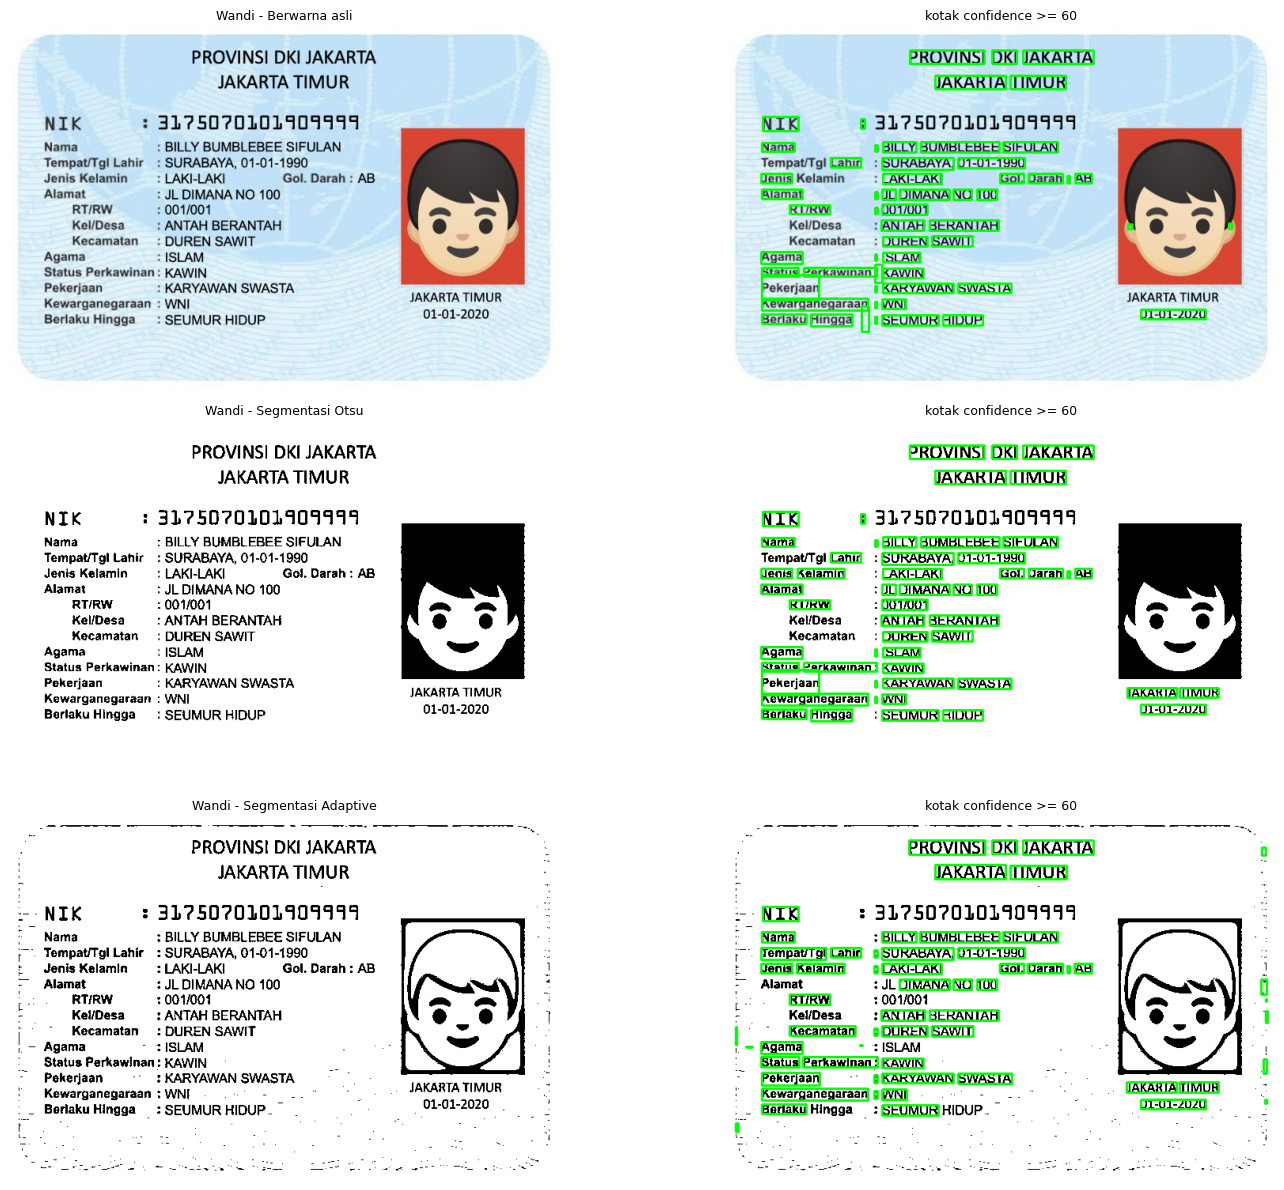

In [6]:
hasil_teks = {}    
hasil_conf = {}    

for nama_anggota, path in daftar_ktp:
    img = cv.imread(path)
    if img is None:
        print('citra tidak ditemukan:', path)
        continue

    varian = [('Berwarna asli', img),
              ('Segmentasi Otsu', versi_otsu(img)),
              ('Segmentasi Adaptive', versi_adaptive(img))]

    print('=' * 72)
    print('ANGGOTA:', nama_anggota, '|', os.path.basename(path))
    print('=' * 72)

    plt.figure(figsize=(16, 12))
    for i, (label, im) in enumerate(varian):
        teks = baca_teks(im)
        kotak, confs = kotak_teks(im)
        rata_conf = float(np.mean(confs)) if confs else 0.0

        hasil_teks[(nama_anggota, label)] = teks
        hasil_conf[(nama_anggota, label)] = rata_conf

        print('\n--- %s ---' % label)
        print(teks.strip())
        print('rata-rata confidence: %.1f (%d kata dikotak)' % (rata_conf, len(confs)))

        plt.subplot(3, 2, i * 2 + 1)
        if im.ndim == 3:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap='gray')
        plt.title(nama_anggota + ' - ' + label, fontsize=9)
        plt.axis('off')

        plt.subplot(3, 2, i * 2 + 2)
        plt.imshow(cv.cvtColor(kotak, cv.COLOR_BGR2RGB))
        plt.title('kotak confidence >= %d' % CONF_MIN, fontsize=9)
        plt.axis('off')
    plt.tight_layout(); plt.show()


## Perbandingan kecocokan

Isi acuan dengan 10 kata/angka yang jelas di KTP. Item dihitung cocok kalau huruf/angkanya
sama dengan acuan (abaikan besar-kecil huruf dan spasi di ujung).


In [7]:
acuan = {
    'Wandi': ['244107020003', 'WANDI', 'REPUBLIK INDONESIA', 'KARTU TANDA PENDUDUK',
              'PROVINSI', 'KABUPATEN', 'LAKI-LAKI', 'ISLAM', 'KEWARGANEGARAAN',
              'BERLAKU HINGGA'],
}


def skor_kecocokan(teks_ocr, daftar_acuan):
    """Cocok kalau item acuan (abaikan besar-kecil huruf) muncul di teks OCR."""
    teks = teks_ocr.lower()
    cocok = 0
    for item in daftar_acuan:
        if item.strip().lower() in teks:
            cocok += 1
    return cocok, 100.0 * cocok / len(daftar_acuan)


print('%-12s %-20s %10s %12s %16s' %
      ('Anggota', 'Citra masukan', 'Terbaca', 'Kecocokan', 'Rata2 conf'))
print('-' * 74)
for nama_anggota, path in daftar_ktp:
    daftar_acuan = acuan.get(nama_anggota, [])
    for label in ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']:
        teks = hasil_teks.get((nama_anggota, label), '')
        if not daftar_acuan:
            print('%-12s %-20s %10s %12s %16s' % (nama_anggota, label, '-', '-',
                                                  '%.1f' % hasil_conf.get((nama_anggota, label), 0)))
            continue
        cocok, persen = skor_kecocokan(teks, daftar_acuan)
        print('%-12s %-20s %7d/%-2d %10.1f%% %14.1f' %
              (nama_anggota, label, cocok, len(daftar_acuan), persen,
               hasil_conf.get((nama_anggota, label), 0)))


Anggota      Citra masukan           Terbaca    Kecocokan       Rata2 conf
--------------------------------------------------------------------------
Wandi        Berwarna asli              5/10       50.0%           90.1
Wandi        Segmentasi Otsu            5/10       50.0%           89.5
Wandi        Segmentasi Adaptive        5/10       50.0%           88.1


## Pertanyaan analisis

**1. Citra mana yang paling tepat?**

Lihat kolom "Terbaca" di tabel, yang terbanyak itu yang paling tepat buat citra tersebut.

**2. Dua kesalahan pembacaan.**

Umumnya angka 0 kebaca O atau 8, huruf I kebaca 1 atau l, teks tipis/miring tidak terbaca,
atau NIK yang panjang kepotong. Tulis dua yang beneran muncul di hasil di atas.

**3. Apakah segmentasi selalu menaikkan ketepatan OCR?**

Tidak. Berguna kalau pencahayaannya tidak merata atau kontrasnya rendah. Tapi di citra yang
sudah bersih, segmentasi malah bisa ngapus detail, nambah bintik, atau nyambungin huruf yang
berdekatan.

**4. Pengaruh warna/pola latar.**

Waktu diubah ke grayscale, latar terang dan tulisan terang bisa punya intensitas mirip, jadi
kontrasnya turun. Latar berpola (garis halus di KTP) bisa dianggap goresan huruf dan munculin
karakter palsu, terutama di adaptive.

**5. Confidence tertinggi = kecocokan tertinggi?**

Belum tentu. Confidence itu seberapa yakin mesin, bukan seberapa benar. Mesin bisa yakin sama
hasil yang salah, jadi kecocokan tetap dinilai dari teksnya.
